In [2]:
# Multi-head causal self-attention in NumPy.
# All numbers are random: we only want to see how attention works,
# not real word meanings (in a real model these are learned).

import math

import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(42)  # fixed seed -> same random numbers every run

tokens = ["I", "love", "learning", "AI"]
n_tokens = len(tokens)
d_model = 8  # length of each token vector
n_heads = 2  # number of attention heads
d_k = d_model // n_heads  # size of each head's Q, K, V vectors (8 // 2 = 4)

# One random vector per token, shape (4, 8): row 0 = "I", row 1 = "love", ...
# In a real model these rows come from the embedding table.
X = rng.standard_normal((n_tokens, d_model))

print("d_model:", d_model)
print("n_heads:", n_heads)
print("d_k    :", d_k)
print("X shape:", X.shape)


def softmax_row(row):
    """Turn one row of scores into probabilities that add up to 1 (-inf -> 0)."""
    exps = []
    for value in row:
        exps.append(math.exp(value))
    total = sum(exps)
    probs = []
    for e in exps:
        probs.append(e / total)
    return probs


def plot_heatmap(matrix, title):
    """Draw attention weights as a grid: rows = looking (queries), columns = looked at (keys)."""
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)

    ax.set_xticks(range(n_tokens))
    ax.set_xticklabels(tokens)
    ax.set_yticks(range(n_tokens))
    ax.set_yticklabels(tokens)
    ax.set_xlabel("Looked at (keys)")
    ax.set_ylabel("Looking (queries)")
    ax.set_title(title)

    # Write each weight inside its box (white text on dark boxes)
    for i in range(n_tokens):
        for j in range(n_tokens):
            value = matrix[i][j]
            if value > 0.5:
                color = "white"
            else:
                color = "black"
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color)

    fig.colorbar(image, ax=ax)
    plt.show()

d_model: 8
n_heads: 2
d_k    : 4
X shape: (4, 8)


In [3]:
def one_head_attention(X, W_Q, W_K, W_V):
    """Run causal self-attention for ONE head. Returns (output, weights)."""
    # 1. Query, key and value of every token for this head -> shape (4, d_k)
    Q = X @ W_Q
    K = X @ W_K
    V = X @ W_V

    # 2. Scores: every query against every key, scaled by sqrt(d_k) -> shape (4, 4)
    scores = (Q @ K.T) / np.sqrt(d_k)

    # 3. Causal mask: a token cannot look at tokens that come after it
    for i in range(n_tokens):
        for j in range(n_tokens):
            if j > i:
                scores[i][j] = -np.inf

    # 4. Softmax each row -> attention weights
    weights = np.zeros((n_tokens, n_tokens))
    for i in range(n_tokens):
        weights[i] = softmax_row(scores[i])

    # 5. Weighted sum of value vectors -> shape (4, d_k)
    output = weights @ V

    return output, weights

In [8]:
scale = np.sqrt(d_model)  # keeps starting weights small, like real models

head_outputs = []  # output of each head
head_attention_weights = []  # attention weights of each head (for heatmaps)

for h in range(n_heads):
    # Each head gets its OWN weight matrices, shape (8, 4) each
    W_Q = rng.standard_normal((d_model, d_k)) / scale
    W_K = rng.standard_normal((d_model, d_k)) / scale
    W_V = rng.standard_normal((d_model, d_k)) / scale

    # Same function, different matrices -> a different "view" of the sentence
    output, weights = one_head_attention(X, W_Q, W_K, W_V)

    head_outputs.append(output)
    head_attention_weights.append(weights)

    print(f"Head {h + 1}: W_Q {W_Q.shape} -> output {output.shape}")
    print(f"Head {h + 1}: W_K {W_K.shape} -> weights {weights.shape}")

Head 1: W_Q (8, 4) -> output (4, 4)
Head 1: W_K (8, 4) -> weights (4, 4)
Head 2: W_Q (8, 4) -> output (4, 4)
Head 2: W_K (8, 4) -> weights (4, 4)


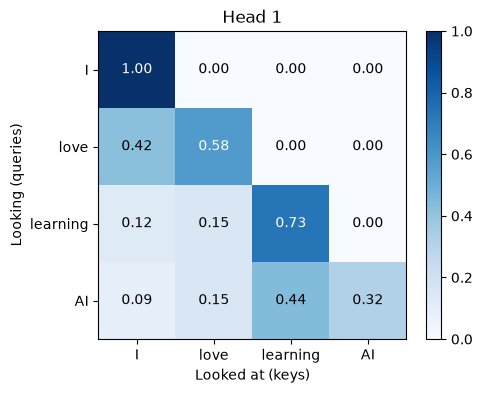

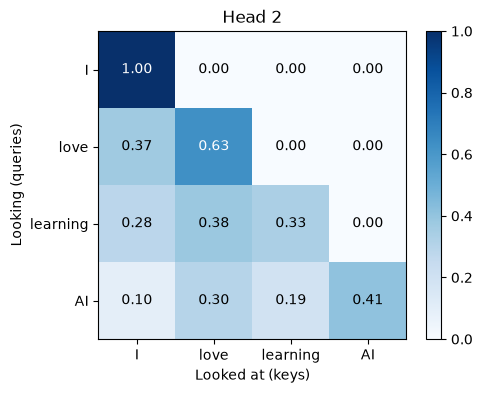

Most-attended token for each row:

         I ->   Head 1: 'I' (1.00)   Head 2: 'I' (1.00)
      love ->   Head 1: 'love' (0.58)   Head 2: 'love' (0.63)
  learning ->   Head 1: 'learning' (0.73)   Head 2: 'love' (0.38)
        AI ->   Head 1: 'learning' (0.44)   Head 2: 'AI' (0.41)


In [ ]:
# One heatmap per head
for h in range(n_heads):
    plot_heatmap(head_attention_weights[h], f"Head {h + 1}")

# Compare: which token does each head look at most, for every row?
print("Most-attended token for each row:\n")
for i in range(n_tokens):
    line = f"{tokens[i]:>10} ->"
    for h in range(n_heads):
        row = head_attention_weights[h][i]

        # Find the biggest weight in this row
        top_j = 0
        for j in range(n_tokens):
            if row[j] > row[top_j]:
                top_j = j

        line += f"   Head {h + 1}: '{tokens[top_j]}' ({row[top_j]:.2f})"
    print(line)

In [11]:
# 1. Concatenate: put both heads' outputs side by side -> shape (4, 8)
combined = np.zeros((n_tokens, n_heads * d_k))
for i in range(n_tokens):
    row = []
    for h in range(n_heads):
        row.extend(head_outputs[h][i])  # 4 numbers from this head
    combined[i] = row

print("Each head's output:", head_outputs[0].shape)
print("Combined shape    :", combined.shape)
print(f"\nCombined row for '{tokens[3]}':")
print("   from Head 1:", np.round(combined[3][:d_k], 2))
print("   from Head 2:", np.round(combined[3][d_k:], 2))

# 2. W_O mixes the heads' information together -> shape (4, 8)
W_O = rng.standard_normal((d_model, d_model)) / scale
mixed = combined @ W_O

# 3. Residual: add the update to the original token vectors
X_new = X + mixed

print("\nOriginal X1 :", X[0])
print("X_new1 :", X_new[0])
print("\nAfter W_O shape  :", mixed.shape)
print("X_new shape      :", X_new.shape, "-> same as X, ready for the next layer")

Each head's output: (4, 4)
Combined shape    : (4, 8)

Combined row for 'AI':
   from Head 1: [-1.64 -0.22  0.09  0.14]
   from Head 2: [-0.49 -0.4  -0.24 -0.22]

Original X1 : [ 0.30471708 -1.03998411  0.7504512   0.94056472 -1.95103519 -1.30217951
  0.1278404  -0.31624259]
X_new1 : [ 0.46713126 -1.59001441  0.20542199  0.97827846 -2.40655788 -2.57240537
  0.16060895  0.94484865]

After W_O shape  : (4, 8)
X_new shape      : (4, 8) -> same as X, ready for the next layer
